# 03 · Результаты

Читает `results/runs.csv` и `results/predictions/` из ноутбука 02 и отвечает на три вопроса
работы: помогает ли sheaf-структура (H1), помогают ли новости (H2), зарабатывает ли стратегия (H3).
Отдельно проверяются горизонт таргета в пять дней и чувствительность выводов к составу выборки.
Таблицы сохраняются в `results/*.md`, графики в `figures/`.

Три методические оговорки. Тестовые окна соседних фолдов пересекаются на три месяца, поэтому
все тесты значимости считаются на двух непересекающихся парах фолдов: A = фолды 0 + 2
(2024-10 … 2025-09) и B = фолды 1 + 3 (2025-01 … 2025-12); среднее по четырём фолдам приводится
как описательная статистика. Наблюдения «тикер × день» внутри одного дня сильно зависимы (общий
рынок), поэтому бутстрэп ресэмплирует целые дни блоками по 10 торговых дней, а не отдельные строки.
Сиды не усредняются в ансамбль: статистики считаются отдельно для каждого сида, а в таблицах
приводится медиана и согласованность вердикта по сидам.

In [1]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import norm

RESULTS, FIG = Path('results'), Path('figures')
runs = pd.read_csv(RESULTS / 'runs.csv')
pred = pd.concat([pd.read_csv(f, parse_dates=['TRADEDATE']) for f in sorted((RESULTS / 'predictions').glob('*.csv.gz'))],
                 ignore_index=True)
pred['pred'] = pred[['p_down', 'p_flat', 'p_up']].values.argmax(1)
pred['score'] = pred['p_up'] - pred['p_down']              # скор для ранжирования в бэктесте
pred['target_ret'] = pred.get('RET_H', pred['FUTURE_RETURN']).fillna(pred['FUTURE_RETURN'])   # доходность, по которой размечен таргет (h = 1 или 5)
comp = pd.read_csv(Path('data') / 'imoex_composition.csv', parse_dates=['DATE'])
snaps = np.sort(comp['DATE'].unique())                     # недельные снимки фактического состава IMOEX
pred['DATE'] = snaps[np.searchsorted(snaps, pred['TRADEDATE'].values, 'right') - 1]
pred = pred.merge(comp[['DATE', 'SECID']].assign(in_index=True), on=['DATE', 'SECID'], how='left').drop(columns='DATE')
pred['in_index'] = pred['in_index'].eq(True)              # бумага входила в индекс в этот день
MODELS = ['NSD', 'GCN', 'GAT', 'MLP', 'LSTM', 'Majority']
TRAINED = MODELS[:5]
PAIRS = {'A (фолды 0+2)': (0, 2), 'B (фолды 1+3)': (1, 3)}
SEED_IDS = sorted(runs['seed'].unique())
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
print(f'{len(runs)} прогонов, {len(pred):,} предсказаний')


def subset(tag, folds, seed, pit=False):
    df = pred.query("grid == '4x18' and tag == @tag and fold in @folds and seed == @seed")
    return df[df['in_index']] if pit else df

550 прогонов, 2,728,440 предсказаний


## Сравнение моделей

Медиана по сидам внутри фолда, затем среднее и стандартное отклонение по четырём фолдам.
IC считается как средний по дням ранговый коэффициент корреляции между скором `P(UP) − P(DOWN)`
и фактической доходностью следующего дня (для горизонта 5 дней — пятидневной): это то, что
напрямую использует бэктест.

In [2]:
keys = ['tag', 'grid', 'fold', 'seed']
g = pred.groupby(keys + ['TRADEDATE'])
pred['rs'], pred['rr'] = g['score'].rank(), g['target_ret'].rank()
ic_day = pred.groupby(keys + ['TRADEDATE'])[['rs', 'rr']].corr().iloc[0::2, 1].droplevel(-1)
runs = runs.merge(ic_day.groupby(keys).mean().rename('ic').reset_index(), on=keys, how='left')


def summary(df):
    per_fold = df.groupby(['tag', 'fold'])[['mcc', 'ic', 'f1', 'f1_down', 'acc']].median()
    agg = per_fold.groupby('tag').agg(['mean', 'std'])
    out = pd.DataFrame({'MCC': agg[('mcc', 'mean')], '± sd по фолдам': agg[('mcc', 'std')],
                        'MCC min…max': per_fold.groupby('tag')['mcc'].agg(lambda s: f'{s.min():+.3f} … {s.max():+.3f}'),
                        'IC': agg[('ic', 'mean')], 'Macro-F1': agg[('f1', 'mean')],
                        'F1-DOWN': agg[('f1_down', 'mean')], 'Accuracy': agg[('acc', 'mean')]})
    return out.sort_values('MCC', ascending=False)


main = summary(runs.query("grid == '4x18' and tag in @MODELS"))
(RESULTS / 'models.md').write_text(main.round(4).to_markdown(), encoding='utf-8')
main.round(4)

,MCC,± sd по фолдам,MCC min…max,IC,Macro-F1,F1-DOWN,Accuracy
tag,,,,,,,
LSTM,0.0675,0.0040,+0.063 … +0.072,0.0290,0.3523,0.3545,0.3677
MLP,0.0043,0.0088,-0.005 … +0.015,0.0271,0.3221,0.3968,0.3458
NSD,0.0023,0.0180,-0.023 … +0.017,0.0112,0.3168,0.4161,0.3478
Majority,0.0000,0.0000,+0.000 … +0.000,NaN,0.1847,0.4364,0.3848
GAT,-0.0030,0.0211,-0.021 … +0.027,0.0015,0.3116,0.3859,0.3284
GCN,-0.0167,0.0130,-0.028 … +0.002,0.0023,0.3085,0.3821,0.3269


Модели с признаками узла (NSD, GCN, GAT и MLP) дают MCC от −0,017 (GCN) до +0,004 (MLP) при разбросе
по фолдам 0,01–0,02: их нельзя отличить от нуля. Единственная модель со стабильно положительным MCC —
LSTM на 20-дневном окне цен и объёмов, без новостей и без графа: +0,068, минимум по фолдам +0,063.
Её преимущество не объясняется доступом к доходности дня t: эта доходность теперь есть и в признаках
остальных моделей, а их MCC остался около нуля. IC положителен у LSTM и MLP (+0,029 и +0,027), у
графовых моделей +0,002…+0,011. Accuracy у Majority (0,385) выше, чем у всех моделей: мажоритарный
класс train (DOWN) на тесте встречается в 36–43 % строк, поэтому accuracy здесь не годится как метрика.

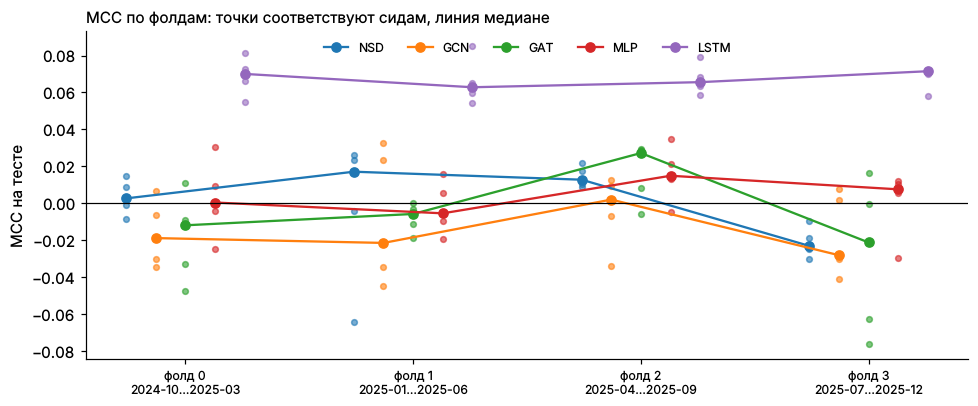

In [3]:
fig, ax = plt.subplots(figsize=(9, 3.8))
sub = runs.query("grid == '4x18' and tag in @TRAINED")
for i, tag in enumerate(TRAINED):
    r = sub[sub.tag == tag]
    ax.scatter(r['fold'] + (i - 2) * 0.13, r['mcc'], s=14, alpha=0.6, color=f'C{i}')
    med = r.groupby('fold')['mcc'].median()
    ax.plot(med.index + (i - 2) * 0.13, med.values, 'o-', color=f'C{i}', ms=6, label=tag)
test_span = pred.query("grid == '4x18'").groupby('fold')['TRADEDATE'].agg(['min', 'max'])
ax.axhline(0, c='k', lw=0.8); ax.set_xticks(test_span.index)
ax.set_xticklabels([f'фолд {i}\n{a:%Y-%m}…{b:%Y-%m}' for i, (a, b) in test_span.iterrows()], fontsize=8)
ax.set_ylabel('MCC на тесте'); ax.legend(ncol=5, fontsize=8, frameon=False, loc='upper center')
ax.set_title('MCC по фолдам: точки соответствуют сидам, линия медиане', fontsize=10, loc='left')
fig.tight_layout(); fig.savefig(FIG / 'mcc_by_fold.png'); plt.show()

## Абляция NSD

Та же процедура; базовая конфигурация `NSD` (hidden 64, d = 4, L = 2, граф corr-MST, новости включены).
Размерность стебля меняется при фиксированной ширине 64 (d = 2, 4, 8).

In [4]:
ABLATION = ['NSD', 'NSD news_off', 'NSD sector', 'NSD d=2', 'NSD d=8', 'NSD L=1', 'NSD L=3']
abl = summary(runs.query("grid == '4x18' and tag in @ABLATION"))
(RESULTS / 'ablation.md').write_text(abl.round(4).to_markdown(), encoding='utf-8')
abl.round(4)

,MCC,± sd по фолдам,MCC min…max,IC,Macro-F1,F1-DOWN,Accuracy
tag,,,,,,,
NSD news_off,0.0316,0.0233,+0.009 … +0.057,0.0280,0.3457,0.3852,0.3522
NSD L=1,0.0062,0.0157,-0.016 … +0.019,0.0162,0.3213,0.4210,0.3485
NSD d=2,0.0058,0.0130,-0.007 … +0.024,0.0178,0.3179,0.4126,0.3507
NSD sector,0.0053,0.0154,-0.017 … +0.018,0.0159,0.3219,0.4333,0.3542
NSD,0.0023,0.0180,-0.023 … +0.017,0.0112,0.3168,0.4161,0.3478
NSD d=8,0.0017,0.0166,-0.023 … +0.013,0.0097,0.3171,0.4165,0.3458
NSD L=3,-0.0019,0.0137,-0.018 … +0.014,0.0166,0.3117,0.4046,0.3498


Отключение новостей улучшает NSD: +0,032 против +0,002, и во всех четырёх фолдах конфигурация без
новостей лучше базовой. Тот же эффект у MLP: +0,032 без новостей против +0,004 с ними (лучше в двух
фолдах из четырёх, но с большим отрывом). Значит, 768 текстовых признаков в текущей привязке служат
источником шума, а не сигнала, и это не свойство конкретной архитектуры. Размерность стебля
(d = 2, 4, 8 при одной ширине), число слоёв и секторный граф вместо корреляционного ничего не меняют:
всё в пределах ±0,004 от базовой конфигурации при разбросе по фолдам 0,013–0,018.

## Парные сравнения

Два теста на каждой непересекающейся паре фолдов, отдельно по каждому сиду:

* **ΔMCC с блочным бутстрэпом по дням.** MCC обеих моделей считается по объединённому тесту пары,
  разница ресэмплируется блоками по 10 торговых дней (2000 повторов); p — двусторонний
  перцентильный.
* **Диболд-Мариано** на дневном ряде доли ошибок направления с HAC-дисперсией Ньюи-Уэста.

Вердикт «значимо» ставится только при согласии всех сидов по знаку и уровню 5 %. Разница средних
по четырём фолдам и число фолдов, где первая модель лучше, приводятся как описательные: фолды
пересекаются, поэтому t-тест по ним не используется.

In [5]:
B_BOOT, BLOCK = 2000, 10


def mcc_conf(C):
    """Многоклассовый MCC по матрицам ошибок (..., 3, 3), как в sklearn."""
    t, p, c, s = C.sum(-1), C.sum(-2), np.trace(C, axis1=-2, axis2=-1), C.sum((-2, -1))
    num = c * s - (t * p).sum(-1)
    den = np.sqrt((s ** 2 - (p * p).sum(-1)) * (s ** 2 - (t * t).sum(-1)))
    return np.where(den > 0, num / np.where(den > 0, den, 1), 0.0)


def block_weights(n, rng, B=B_BOOT, L=BLOCK):
    """Число вхождений каждого дня в B ресэмплах moving block bootstrap: (B, n)."""
    starts = rng.integers(0, max(n - L, 0) + 1, size=(B, -(-n // L)))
    days_ = (starts[..., None] + np.arange(L)).reshape(B, -1)[:, :n]
    return np.stack([np.bincount(d, minlength=n) for d in days_]).astype(float)


def boot_p(stat, boot):
    return min(1.0, 2 * min((boot <= 0).mean(), (boot >= 0).mean()) + 1 / len(boot))


def daily_conf(df, days_):
    c = np.zeros((len(days_), 9))
    np.add.at(c, (days_.get_indexer(df['TRADEDATE']), df['y'].values * 3 + df['pred'].values), 1)
    return c


def delta_mcc(pa, pb, seed):
    days_ = pd.DatetimeIndex(sorted(set(pa['TRADEDATE']) & set(pb['TRADEDATE'])))
    ca, cb = daily_conf(pa, days_), daily_conf(pb, days_)
    W = block_weights(len(days_), np.random.default_rng(seed))
    stat = mcc_conf(ca.sum(0).reshape(3, 3)) - mcc_conf(cb.sum(0).reshape(3, 3))
    boot = mcc_conf((W @ ca).reshape(-1, 3, 3)) - mcc_conf((W @ cb).reshape(-1, 3, 3))
    return stat, boot_p(stat, boot)


def dm_test(la, lb):
    d = np.asarray(la) - np.asarray(lb); n = len(d); h = int(1.5 * n ** (1 / 3)); d0 = d - d.mean()
    lrv = d0 @ d0 / n + 2 * sum((1 - j / (h + 1)) * (d0[j:] @ d0[:-j]) / n for j in range(1, h + 1))
    stat = d.mean() / np.sqrt(max(lrv, 1e-12) / n)
    return stat, 2 * (1 - norm.cdf(abs(stat)))


def verdict(stats, ps):
    s = np.sign(stats)
    if len(set(s[s != 0])) > 1: return 'знак разный'
    if (ps < .05).all(): return 'значимо'
    return 'не все сиды' if (ps < .05).any() else 'не значимо'


def daily_loss(df):
    return (df['pred'] != df['y']).groupby(df['TRADEDATE']).mean()


def compare(pairs):
    rows = []
    for a, b in pairs:
        ma = runs.query("grid == '4x18' and tag == @a").groupby('fold')['mcc'].median()
        mb = runs.query("grid == '4x18' and tag == @b").groupby('fold')['mcc'].median()
        row = {'сравнение': f'{a} − {b}', 'Δ MCC (4 фолда)': (ma - mb).mean(), 'фолдов Δ>0': int((ma > mb).sum())}
        for name, folds in PAIRS.items():
            bt, dm = [], []
            for s in SEED_IDS:
                pa, pb = subset(a, folds, s), subset(b, folds, s)
                bt.append(delta_mcc(pa, pb, seed=s))
                la, lb = daily_loss(pa).align(daily_loss(pb), join='inner')
                dm.append(dm_test(la, lb))                   # DM < 0: у первой модели ошибка меньше
            bt, dm = np.array(bt), np.array(dm)
            row[f'ΔMCC {name}'] = f'{np.median(bt[:, 0]):+.3f} ({verdict(bt[:, 0], bt[:, 1])})'
            row[f'DM {name}'] = f'{np.median(dm[:, 0]):+.2f} ({verdict(dm[:, 0], dm[:, 1])})'
        rows.append(row)
    return pd.DataFrame(rows).set_index('сравнение')


COMPARE = [('NSD', 'GCN'), ('NSD', 'GAT'), ('NSD', 'MLP'), ('NSD', 'LSTM'), ('MLP', 'LSTM'),
           ('NSD news_off', 'NSD'), ('MLP news_off', 'MLP'), ('NSD sector', 'NSD')]
tests = compare(COMPARE)
(RESULTS / 'tests.md').write_text(tests.round(4).to_markdown(), encoding='utf-8')
tests.round(4)

,Δ MCC (4 фолда),фолдов Δ>0,ΔMCC A (фолды 0+2),DM A (фолды 0+2),ΔMCC B (фолды 1+3),DM B (фолды 1+3)
сравнение,,,,,,
NSD − GCN,0.0190,4,+0.023 (знак разный),-2.59 (не все сиды),-0.005 (знак разный),-0.62 (знак разный)
NSD − GAT,0.0053,2,+0.010 (знак разный),-1.89 (не все сиды),+0.003 (знак разный),-0.59 (не значимо)
NSD − MLP,-0.0020,2,-0.001 (знак разный),-0.16 (знак разный),-0.012 (знак разный),+0.78 (знак разный)
NSD − LSTM,-0.0652,0,-0.063 (значимо),+1.49 (не значимо),-0.082 (значимо),+1.65 (знак разный)
MLP − LSTM,-0.0632,0,-0.071 (значимо),+0.90 (не все сиды),-0.086 (значимо),+1.27 (не все сиды)
NSD news_off − NSD,0.0293,4,+0.029 (знак разный),+0.23 (знак разный),+0.051 (не все сиды),-1.02 (знак разный)
MLP news_off − MLP,0.0275,2,+0.030 (не значимо),+0.40 (знак разный),+0.048 (не все сиды),-1.02 (не значимо)
NSD sector − NSD,0.0030,3,+0.005 (знак разный),-0.96 (знак разный),+0.006 (знак разный),-1.99 (знак разный)


NSD статистически неотличим от GCN, GAT и MLP: в бутстрэпе ΔMCC знак меняется от сида к сиду на обеих
парах фолдов. Средняя по фолдам разница NSD − GCN = +0,019 (все четыре фолда) объясняется скорее тем,
что GCN ниже нуля, чем тем, что NSD выше. LSTM значимо лучше и NSD, и MLP на обеих парах при всех сидах
(ΔMCC от −0,06 до −0,09). Тест DM на доле ошибок этих различий не находит: LSTM выигрывает в балансе
угаданных классов, а не в общей доле совпадений (accuracy 0,368 против 0,346–0,348). Отключение
новостей даёт около +0,03 MCC и у NSD, и у MLP; по строгому критерию «значимо при всех сидах» эффект
незначим (на паре B значим у части сидов), но его знак устойчиво противоположен гипотезе H2.

## Направленная предсказуемость

Бинаризация «класс против остальных» для UP и для DOWN, статистика Пезарана-Тиммерманна:
избыток доли совпадений `P̂ − P*` над долей, ожидаемой при независимости прогноза и факта
(в п. п.). Классическая z-статистика PT предполагает независимые наблюдения, а строки одного дня
зависимы, поэтому значимость оценивается тем же блочным бутстрэпом по дням.

In [6]:
def pt_daily(df, cls, days_):
    """Дневные суммы для PT: [n, Σa, Σb, Σab, Σ(1−a)(1−b)]."""
    a, b = (df['y'].values == cls).astype(float), (df['pred'].values == cls).astype(float)
    out = np.zeros((len(days_), 5)); d = days_.get_indexer(df['TRADEDATE'])
    for j, v in enumerate([np.ones_like(a), a, b, a * b, (1 - a) * (1 - b)]):
        np.add.at(out[:, j], d, v)
    return out


def pt_excess(s):
    n, sa, sb, sab, s00 = np.moveaxis(s, -1, 0)
    py, pz = sa / n, sb / n
    return (sab + s00) / n - (py * pz + (1 - py) * (1 - pz))


rows = []
for tag in TRAINED + ['NSD news_off', 'MLP news_off']:
    for name, folds in PAIRS.items():
        row = {'модель': tag, 'пара': name}
        for cls, cname in ((2, 'UP'), (0, 'DOWN')):
            st = []
            for s in SEED_IDS:
                df = subset(tag, folds, s)
                days_ = pd.DatetimeIndex(sorted(df['TRADEDATE'].unique()))
                dly = pt_daily(df, cls, days_)
                W = block_weights(len(days_), np.random.default_rng(s))
                stat = pt_excess(dly.sum(0)); st.append((stat, boot_p(stat, pt_excess(W @ dly))))
            st = np.array(st)
            row[f'PT {cname}, п. п.'] = f'{100 * np.median(st[:, 0]):+.2f} ({verdict(st[:, 0], st[:, 1])})'
        rows.append(row)
pt = pd.DataFrame(rows).set_index(['модель', 'пара'])
(RESULTS / 'pt_test.md').write_text(pt.to_markdown(), encoding='utf-8')
pt

PT UP, п. п.       PT DOWN, п. п.
модель       пара                                                   
NSD          A (фолды 0+2)  -0.08 (знак разный)  +0.37 (знак разный)
             B (фолды 1+3)  -0.69 (не все сиды)  +0.12 (знак разный)
GCN          A (фолды 0+2)   -1.65 (не значимо)  +0.01 (знак разный)
             B (фолды 1+3)   -2.10 (не значимо)  -0.55 (знак разный)
GAT          A (фолды 0+2)  -0.30 (знак разный)  -0.73 (знак разный)
             B (фолды 1+3)  -1.44 (не все сиды)   -0.70 (не значимо)
MLP          A (фолды 0+2)  -0.35 (знак разный)   +0.76 (не значимо)
             B (фолды 1+3)   -0.87 (не значимо)  +0.34 (знак разный)
LSTM         A (фолды 0+2)      +2.72 (значимо)  +1.57 (не все сиды)
             B (фолды 1+3)      +1.76 (значимо)      +2.83 (значимо)
NSD news_off A (фолды 0+2)   +0.63 (не значимо)  +0.41 (знак разный)
             B (фолды 1+3)   +0.26 (не значимо)  +1.11 (не все сиды)
MLP news_off A (фолды 0+2)   +0.58 (не значимо)   +0.36 (не значимо)
             B (фолды 1+3)  +0.34 (знак разный)   +1.04 (не значимо)

Устойчивый направленный сигнал есть только у LSTM: по UP на обеих парах при всех сидах (+2,7 и +1,8 п. п.
совпадений сверх ожидаемых при независимости), по DOWN — на паре B (+2,8 п. п.), на паре A не у всех
сидов. У NSD, GCN, GAT и MLP статистика либо меняет знак от сида к сиду, либо незначима. Классическая
z-статистика PT на этих данных завышала бы значимость: она считает 10–12 тысяч строк пары независимыми,
хотя строки одного дня связаны общим движением рынка.

## Бэктест

Стратегия: каждый день long equal-weight из десяти бумаг с наибольшим `P(UP) − P(DOWN)`, дневная
ребалансировка. Доходности ценовые: скорректированы на сплиты, но не на дивиденды (публичный ISS
их не отдаёт), поэтому в дни отсечки занижены и у стратегий, и у бенчмарка. Бенчмарк:
равновзвешенный портфель всех размеченных бумаг (он считается из тех же данных, что и стратегии,
и не зависит от весов индекса). Оборот: доля портфеля, заменяемая за день,
в первый день — 100 % (покупка портфеля); по нему считается доходность за вычетом комиссии 5 и 10 б.п.
round-trip. Для бенчмарка издержки не вычитаются, что смещает сравнение в его пользу слабо: его
дневной оборот мал. Sharpe приводится без вычета безрисковой ставки; поскольку ключевая ставка ЦБ
в тестовый период составляла 16–21 % годовых, главное сравнение здесь — с бенчмарком:
активная доходность к EW и information ratio (IR).

In [7]:
def topk(df, k=10, h=1):
    """Long top-k по скору. При h > 1 — h пересекающихся когорт (Jegadeesh, Titman, 1993): портфель дня t —
    среднее равновзвешенных top-k, сформированных в дни t−h+1 … t, то есть каждая когорта держится h дней."""
    top = df.sort_values(['TRADEDATE', 'score'], ascending=[True, False]).groupby('TRADEDATE').head(k)
    w = (pd.crosstab(top['TRADEDATE'], top['SECID']) / k).rolling(h, min_periods=1).mean()   # веса, дни × бумаги
    R = df.pivot(index='TRADEDATE', columns='SECID', values='FUTURE_RETURN').reindex_like(w)
    ret = (w * R.fillna(0)).sum(1)                              # бумага без торгов на следующий день: доходность 0
    turn = w.diff().abs().sum(1) / 2; turn.iloc[0] = 1.0        # доля портфеля, заменяемая за день; в первый день — покупка
    return ret, turn


def perf(r, ew, turn=None):
    eq, act = (1 + r).cumprod(), (r - ew).dropna()
    out = {'накопл.': eq.iloc[-1] - 1, 'Sharpe (без r_f)': r.mean() / r.std() * np.sqrt(252),
           'макс. просадка': (eq / eq.cummax() - 1).min()}
    if turn is not None:
        out['актив. к EW'] = (1 + r).prod() - (1 + ew).prod()
        out['IR к EW'] = act.mean() / act.std() * np.sqrt(252)
        out['оборот/день'] = turn.mean()
        for bp in (5, 10):
            net = r - turn * bp / 1e4
            out[f'накопл. при {bp} б.п.'] = (1 + net).prod() - 1
            out[f'актив. при {bp} б.п.'] = (1 + net).prod() - (1 + ew).prod()
    return out


def backtest(strategies, bench='Majority', h=1, pit=False):
    """Медиана метрик по сидам для каждой пары фолдов; бенчмарк — равновзвешенный портфель размеченных бумаг."""
    rows, curves = [], {}
    for name, folds in PAIRS.items():
        ew = subset(bench, folds, SEED_IDS[0], pit).groupby('TRADEDATE')['FUTURE_RETURN'].mean()
        for tag in strategies:
            per_seed = []
            for s in SEED_IDS:
                r, turn = topk(subset(tag, folds, s, pit), h=h)
                per_seed.append(perf(r, ew.reindex(r.index), turn)); curves[(name, tag, s)] = (1 + r).cumprod()
            rows.append({'пара': name, 'стратегия': f'{tag} top-10', **pd.DataFrame(per_seed).median().to_dict()})
        rows.append({'пара': name, 'стратегия': 'равновзвешенный портфель', **perf(ew, ew)})
        curves[(name, 'EW', 0)] = (1 + ew).cumprod()
    return pd.DataFrame(rows).set_index(['пара', 'стратегия']), curves


STRATEGIES = TRAINED + ['NSD news_off', 'MLP news_off']
bt, curves = backtest(STRATEGIES)
(RESULTS / 'backtest.md').write_text(bt.round(4).to_markdown(), encoding='utf-8')
bt.round(4)

накопл.  Sharpe (без r_f)  \
пара          стратегия                                             
A (фолды 0+2) NSD top-10                -0.0690           -0.1230   
              GCN top-10                -0.0720           -0.1545   
              GAT top-10                -0.0458           -0.0434   
              MLP top-10                -0.0223            0.0533   
              LSTM top-10               -0.0613           -0.0943   
              NSD news_off top-10       -0.0083            0.1040   
              MLP news_off top-10       -0.0752           -0.1597   
              равновзвешенный портфель  -0.0725           -0.1663   
B (фолды 1+3) NSD top-10                -0.0121            0.0859   
              GCN top-10                -0.0310           -0.0032   
              GAT top-10                -0.0312            0.0013   
              MLP top-10                 0.1373            0.6168   
              LSTM top-10               -0.0010            0.1275   
              NSD news_off top-10        0.0365            0.2663   
              MLP news_off top-10       -0.0042            0.1108   
              равновзвешенный портфель  -0.0357           -0.0341   

                                        макс. просадка  актив. к EW  IR к EW  \
пара          стратегия                                                        
A (фолды 0+2) NSD top-10                       -0.2150       0.0035   0.1171   
              GCN top-10                       -0.2125       0.0005   0.0283   
              GAT top-10                       -0.2144       0.0267   0.4112   
              MLP top-10                       -0.2060       0.0502   0.7090   
              LSTM top-10                      -0.2088       0.0112   0.2001   
              NSD news_off top-10              -0.2236       0.0642   0.8477   
              MLP news_off top-10              -0.2440      -0.0027   0.0003   
              равновзвешенный портфель         -0.2063          NaN      NaN   
B (фолды 1+3) NSD top-10                       -0.2135       0.0236   0.4240   
              GCN top-10                       -0.2248       0.0047   0.1124   
              GAT top-10                       -0.2348       0.0045   0.1225   
              MLP top-10                       -0.2015       0.1730   2.5361   
              LSTM top-10                      -0.2203       0.0347   0.5002   
              NSD news_off top-10              -0.2382       0.0722   0.9948   
              MLP news_off top-10              -0.2493       0.0315   0.4741   
              равновзвешенный портфель         -0.2588          NaN      NaN   

                                        оборот/день  накопл. при 5 б.п.  \
пара          стратегия                                                   
A (фолды 0+2) NSD top-10                     0.7004             -0.1485   
              GCN top-10                     0.7141             -0.1553   
              GAT top-10                     0.7216             -0.1312   
              MLP top-10                     0.6980             -0.1069   
              LSTM top-10                    0.5725             -0.1275   
              NSD news_off top-10            0.6502             -0.0873   
              MLP news_off top-10            0.6325             -0.1464   
              равновзвешенный портфель          NaN                 NaN   
B (фолды 1+3) NSD top-10                     0.7146             -0.0962   
              GCN top-10                     0.7182             -0.1152   
              GAT top-10                     0.7253             -0.1180   
              MLP top-10                     0.7043              0.0404   
              LSTM top-10                    0.4866             -0.0663   
              NSD news_off top-10            0.6055             -0.0488   
              MLP news_off top-10            0.6221             -0.0779   
              равновзвешенный портфель          NaN                 NaN   

     

Без издержек почти все стратегии обгоняют равновзвешенный портфель на обеих парах. С заметным
отрывом на обеих парах — NSD без новостей (+6,4 и +7,2 п. п. активной доходности, IR 0,85 и 0,99)
и MLP (+5,0 и +17,3 п. п.; IR 0,71 и 2,5), но у MLP почти весь результат даёт одна пара. При обороте 49–73 % портфеля в день комиссия 5 б.п. round-trip съедает
преимущество: после издержек бенчмарк обгоняет только MLP на паре B (+7,6 п. п.), на паре A он
проигрывает (−3,4 п. п.). Лучший MCC у LSTM не превращается в лучшую доходность: +1,1 и +3,5 п. п.
к бенчмарку без издержек и отрицательная активная доходность после. Абсолютные доходности всех
стратегий за год не дотягивают до ключевой ставки 16–21 %: ни одна не обыгрывает депозит.

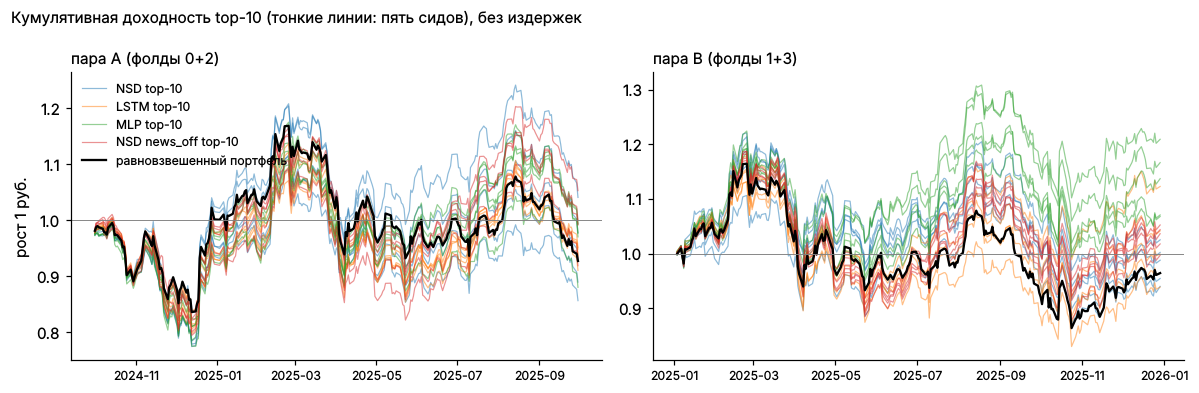

In [8]:
def plot_curves(curves, tags, title, path):
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
    for ax, name in zip(axes, PAIRS):
        for i, tag in enumerate(tags):
            for s in SEED_IDS:
                ax.plot(curves[(name, tag, s)], color=f'C{i}', lw=0.8, alpha=0.5, label=f'{tag} top-10' if s == SEED_IDS[0] else None)
        ax.plot(curves[(name, 'EW', 0)], color='k', lw=1.5, label='равновзвешенный портфель')
        ax.axhline(1, c='grey', lw=0.6); ax.set_title(f'пара {name}', fontsize=10, loc='left'); ax.tick_params(axis='x', labelsize=8)
    axes[0].set_ylabel('рост 1 руб.'); axes[0].legend(fontsize=8, frameon=False)
    fig.suptitle(title, fontsize=10, x=0.01, ha='left')
    fig.tight_layout(); fig.savefig(path); plt.show()


plot_curves(curves, ['NSD', 'LSTM', 'MLP', 'NSD news_off'],
            'Кумулятивная доходность top-10 (тонкие линии: пять сидов), без издержек', FIG / 'backtest.png')

## Чувствительность к сетке валидации

Та же модель NSD и тот же код на контрольной сетке 24/6/6 (два длинных фолда, у второго
тест три месяца) и на основной 18/6/6 (четыре фолда по шесть месяцев); по фолдам
приводятся медиана и разброс по пяти сидам.

In [9]:
grid_cmp = (runs.query("tag == 'NSD'").groupby(['grid', 'fold'])['mcc']
                .agg(медиана='median', min='min', max='max').round(4))
grid_cmp.loc[('4x18', 'среднее'), :] = [grid_cmp.loc['4x18', 'медиана'].mean(), np.nan, np.nan]
grid_cmp.loc[('2x24', 'среднее'), :] = [grid_cmp.loc['2x24', 'медиана'].mean(), np.nan, np.nan]
(RESULTS / 'grid_comparison.md').write_text(grid_cmp.round(4).to_markdown(), encoding='utf-8')
grid_cmp.round(4)

медиана     min     max
grid fold                            
2x24 0         0.0399  0.0264  0.0594
     1         0.0358  0.0208  0.0627
4x18 0         0.0026 -0.0084  0.0145
     1         0.0171 -0.0644  0.0261
     2         0.0127  0.0087  0.0219
     3        -0.0232 -0.0304 -0.0096
     среднее   0.0023     NaN     NaN
2x24 среднее   0.0378     NaN     NaN

На двух длинных фолдах NSD даёт +0,038 при разбросе по сидам от +0,021 до +0,063, на четырёх +0,002.
Разброс по сидам внутри одного фолда (до 0,09 на фолде 1) сопоставим с разницей между LSTM и GCN:
оценка по одному сиду и двум фолдам могла бы показать любое значение из этого диапазона. Отсюда
протокол: медиана по пяти сидам, среднее по четырём фолдам, тесты на непересекающихся парах фолдов
с бутстрэпом по дням.

## Дополнительные эксперименты

Источник сигнала LSTM (варианты по каналам окна, длине окна и архитектуре) и проверка H2 на новостях
только с явной привязкой к эмитенту. Та же процедура: медиана по сидам, среднее по фолдам, бутстрэп
по дням на непересекающихся парах фолдов.

In [10]:
EXTRA = ['LSTM', 'LSTM ret', 'LSTM vol', 'LSTM 5d', 'MLP 20d', 'MLP',
         'NSD', 'NSD news_off', 'NSD news L1', 'MLP news_off', 'MLP news L1']
extra = summary(runs.query("grid == '4x18' and tag in @EXTRA"))
(RESULTS / 'extra.md').write_text(extra.round(4).to_markdown(), encoding='utf-8')
extra.round(4)

,MCC,± sd по фолдам,MCC min…max,IC,Macro-F1,F1-DOWN,Accuracy
tag,,,,,,,
LSTM,0.0675,0.0040,+0.063 … +0.072,0.0290,0.3523,0.3545,0.3677
LSTM ret,0.0585,0.0183,+0.034 … +0.074,0.0124,0.3597,0.3446,0.3694
LSTM 5d,0.0495,0.0110,+0.040 … +0.063,0.0210,0.3555,0.3664,0.3623
LSTM vol,0.0330,0.0142,+0.015 … +0.049,0.0309,0.3239,0.4150,0.3464
MLP news_off,0.0319,0.0255,+0.006 … +0.056,0.0275,0.3485,0.3894,0.3529
NSD news_off,0.0316,0.0233,+0.009 … +0.057,0.0280,0.3457,0.3852,0.3522
MLP 20d,0.0309,0.0099,+0.022 … +0.044,0.0236,0.3501,0.3947,0.3576
MLP news L1,0.0248,0.0130,+0.009 … +0.039,0.0312,0.3432,0.3500,0.3473
NSD news L1,0.0223,0.0114,+0.009 … +0.034,0.0318,0.3422,0.3930,0.3498


In [11]:
extra_tests = compare([('LSTM ret', 'LSTM'), ('LSTM vol', 'LSTM'), ('LSTM 5d', 'LSTM'), ('MLP 20d', 'LSTM'), ('MLP 20d', 'MLP'),
                       ('NSD news L1', 'NSD'), ('NSD news L1', 'NSD news_off'), ('MLP news L1', 'MLP news_off')])
(RESULTS / 'extra_tests.md').write_text(extra_tests.round(4).to_markdown(), encoding='utf-8')
extra_tests.round(4)

,Δ MCC (4 фолда),фолдов Δ>0,ΔMCC A (фолды 0+2),DM A (фолды 0+2),ΔMCC B (фолды 1+3),DM B (фолды 1+3)
сравнение,,,,,,
LSTM ret − LSTM,-0.0090,2,-0.015 (не все сиды),+0.93 (не все сиды),-0.004 (знак разный),-1.52 (знак разный)
LSTM vol − LSTM,-0.0345,0,-0.037 (не все сиды),+1.78 (не все сиды),-0.044 (значимо),+0.88 (не все сиды)
LSTM 5d − LSTM,-0.0180,1,-0.024 (не все сиды),+1.99 (не все сиды),-0.015 (не все сиды),-1.01 (знак разный)
MLP 20d − LSTM,-0.0366,0,-0.042 (не все сиды),+1.12 (не значимо),-0.046 (значимо),+0.41 (знак разный)
MLP 20d − MLP,0.0266,4,+0.026 (не значимо),-0.40 (знак разный),+0.037 (не все сиды),-1.00 (знак разный)
NSD news L1 − NSD,0.0200,4,+0.016 (не значимо),+0.51 (не значимо),+0.032 (не все сиды),-1.01 (знак разный)
NSD news L1 − NSD news_off,-0.0093,2,-0.003 (знак разный),+1.52 (знак разный),-0.015 (не все сиды),+0.58 (знак разный)
MLP news L1 − MLP news_off,-0.0071,2,-0.008 (знак разный),+0.47 (знак разный),-0.017 (не все сиды),+1.61 (не все сиды)


**Откуда сигнал у LSTM.** Большую часть сигнала несут доходности: LSTM только на них даёт +0,059
против +0,068 у полной модели, и разница незначима. Объёмы сами по себе тоже информативны (+0,033),
но заметно слабее; на паре B отставание значимо. Укорочение окна до 5 дней стоит около 0,02 MCC
(+0,050, незначимо). MLP на том же 20-дневном окне даёт лишь +0,031 — столько же, сколько MLP на
пяти лагах без новостей — и значимо уступает LSTM на паре B. Значит, преимущество LSTM не в длине
истории как таковой, а в последовательной обработке ряда доходностей.

**H2 на явной привязке.** Новости только с явным упоминанием эмитента дают +0,022 (NSD) и +0,025 (MLP):
лучше широковещательной привязки во всех четырёх фолдах (+0,020, незначимо), но не лучше полного
отказа от новостей (−0,009 и −0,007, знак меняется от сида к сиду). Вред от новостей в основной
конфигурации создаёт широковещательная привязка L2/L3; сами новости с явной привязкой нейтральны:
сигнала сверх цен они не добавляют.

## Горизонт 5 дней

Те же восемь конфигураций с таргетом на пять сессий вперёд (t+1 … t+5, терцили тикера на train;
ноутбук 02). Метрики и тесты считаются так же; таргеты соседних дней перекрываются на четыре дня,
и блоки бутстрэпа по 10 дней это покрывают. Бэктест — пересекающиеся портфели (Jegadeesh, Titman,
1993): каждый день формируется top-10 по скору и держится пять дней, портфель дня — среднее пяти
последних когорт, поэтому за день заменяется не больше пятой части портфеля.

In [12]:
H5 = ['LSTM h=5', 'MLP h=5', 'NSD h=5', 'GAT h=5', 'GCN h=5', 'Majority h=5', 'NSD news_off h=5', 'MLP news_off h=5']
h5 = summary(runs.query("grid == '4x18' and tag in @H5"))
(RESULTS / 'horizon5.md').write_text(h5.round(4).to_markdown(), encoding='utf-8')
h5.round(4)

,MCC,± sd по фолдам,MCC min…max,IC,Macro-F1,F1-DOWN,Accuracy
tag,,,,,,,
LSTM h=5,0.0339,0.0268,+0.003 … +0.063,0.0017,0.3273,0.4343,0.3699
NSD news_off h=5,0.0114,0.0155,-0.008 … +0.027,0.0138,0.3036,0.3581,0.3280
MLP news_off h=5,0.0107,0.0227,-0.019 … +0.034,0.0111,0.3219,0.4214,0.3497
MLP h=5,0.0027,0.0234,-0.028 … +0.023,0.0032,0.3072,0.3848,0.3307
Majority h=5,0.0000,0.0000,+0.000 … +0.000,NaN,0.1769,0.3090,0.3664
NSD h=5,-0.0013,0.0316,-0.040 … +0.037,0.0005,0.3135,0.4253,0.3390
GCN h=5,-0.0024,0.0320,-0.047 … +0.025,-0.0023,0.3072,0.4076,0.3336
GAT h=5,-0.0027,0.0348,-0.043 … +0.040,-0.0061,0.2993,0.4139,0.3306


In [13]:
h5_tests = compare([('NSD h=5', 'GCN h=5'), ('NSD h=5', 'GAT h=5'), ('NSD h=5', 'MLP h=5'), ('NSD h=5', 'LSTM h=5'),
                    ('MLP h=5', 'LSTM h=5'), ('NSD news_off h=5', 'NSD h=5'), ('MLP news_off h=5', 'MLP h=5')])
(RESULTS / 'horizon5_tests.md').write_text(h5_tests.round(4).to_markdown(), encoding='utf-8')
h5_tests

,Δ MCC (4 фолда),фолдов Δ>0,ΔMCC A (фолды 0+2),DM A (фолды 0+2),ΔMCC B (фолды 1+3),DM B (фолды 1+3)
сравнение,,,,,,
NSD h=5 − GCN h=5,0.001077,3,+0.004 (знак разный),+0.16 (знак разный),+0.021 (знак разный),-0.97 (знак разный)
NSD h=5 − GAT h=5,0.001334,2,+0.009 (знак разный),-1.37 (знак разный),+0.017 (знак разный),-0.68 (знак разный)
NSD h=5 − MLP h=5,-0.004020,2,+0.009 (знак разный),-0.20 (знак разный),-0.002 (знак разный),+0.30 (знак разный)
NSD h=5 − LSTM h=5,-0.035291,0,-0.014 (знак разный),+0.56 (знак разный),-0.074 (не все сиды),+1.47 (не все сиды)
MLP h=5 − LSTM h=5,-0.031271,1,-0.015 (знак разный),+0.90 (знак разный),-0.076 (не все сиды),+1.91 (не все сиды)
NSD news_off h=5 − NSD h=5,0.012725,2,-0.015 (знак разный),+1.28 (не все сиды),+0.027 (знак разный),-0.41 (знак разный)
MLP news_off h=5 − MLP h=5,0.008007,2,-0.009 (знак разный),+0.16 (знак разный),+0.057 (не значимо),-1.59 (знак разный)


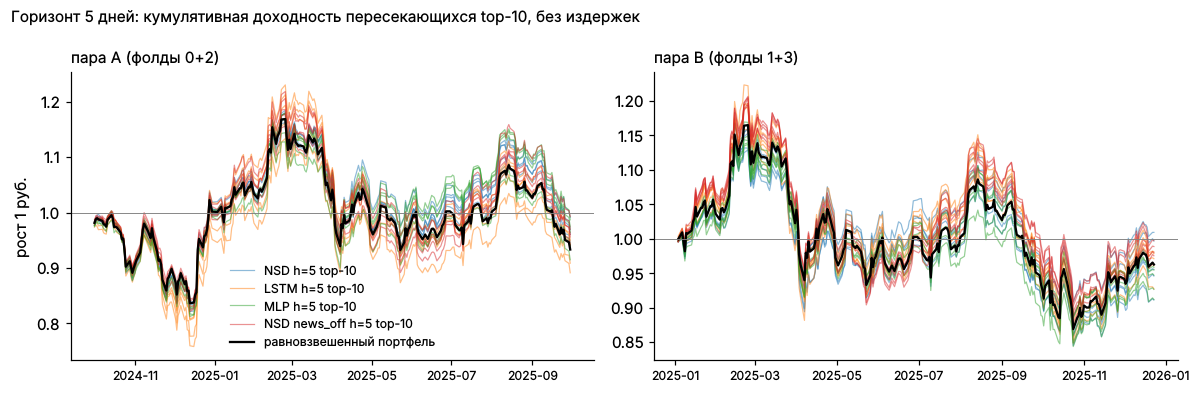

накопл.  актив. к EW  IR к EW  \
пара          стратегия                                                 
A (фолды 0+2) LSTM h=5 top-10           -0.0651       0.0016   0.0442   
              MLP h=5 top-10            -0.0357       0.0310   0.9236   
              NSD h=5 top-10            -0.0397       0.0270   0.7528   
              GAT h=5 top-10            -0.0603       0.0065   0.1971   
              GCN h=5 top-10            -0.0233       0.0434   1.2335   
              NSD news_off h=5 top-10   -0.0396       0.0272   0.7452   
              MLP news_off h=5 top-10   -0.0222       0.0445   0.9695   
              равновзвешенный портфель  -0.0667          NaN      NaN   
B (фолды 1+3) LSTM h=5 top-10           -0.0290       0.0084   0.2410   
              MLP h=5 top-10            -0.0530      -0.0156  -0.4467   
              NSD h=5 top-10            -0.0446      -0.0071  -0.1836   
              GAT h=5 top-10            -0.0347       0.0027   0.0701   
              GCN h=5 top-10            -0.0526      -0.0152  -0.4063   
              NSD news_off h=5 top-10   -0.0203       0.0172   0.3900   
              MLP news_off h=5 top-10   -0.0129       0.0246   0.5252   
              равновзвешенный портфель  -0.0374          NaN      NaN   

                                        оборот/день  актив. при 5 б.п.  \
пара          стратегия                                                  
A (фолды 0+2) LSTM h=5 top-10                0.1243            -0.0136   
              MLP h=5 top-10                 0.1442             0.0131   
              NSD h=5 top-10                 0.1481             0.0090   
              GAT h=5 top-10                 0.1455            -0.0108   
              GCN h=5 top-10                 0.1436             0.0257   
              NSD news_off h=5 top-10        0.1460             0.0092   
              MLP news_off h=5 top-10        0.1422             0.0271   
              равновзвешенный портфель          NaN                NaN   
B (фолды 1+3) LSTM h=5 top-10                0.1562            -0.0089   
              MLP h=5 top-10                 0.1460            -0.0318   
              NSD h=5 top-10                 0.1438            -0.0241   
              GAT h=5 top-10                 0.1499            -0.0152   
              GCN h=5 top-10                 0.1449            -0.0317   
              NSD news_off h=5 top-10        0.1449             0.0000   
              MLP news_off h=5 top-10        0.1430             0.0074   
              равновзвешенный портфель          NaN                NaN   

                                        актив. при 10 б.п.  
пара          стратегия                                     
A (фолды 0+2) LSTM h=5 top-10                      -0.0286  
              MLP h=5 top-10                       -0.0045  
              NSD h=5 top-10                       -0.0086  
              GAT h=5 top-10                       -0.0278  
              GCN h=5 top-10                        0.0083  
              NSD news_off h=5 top-10              -0.0085  
              MLP news_off h=5 top-10               0.0099  
              равновзвешенный портфель                 NaN  
B (фолды 1+3) LSTM h=5 top-10                      -0.0260  
              MLP h=5 top-10                       -0.0477  
              NSD h=5 top-10                       -0.0408  
              GAT h=5 top-10                       -0.0328  
              GCN h=5 top-10                       -0.0480  
              NSD news_off h=5 top-10              -0.0168  
              MLP news_off h=5 top-10              -0.0096  
              равновзвешенный портфель                 NaN

In [14]:
bt5, curves5 = backtest([t for t in H5 if not t.startswith('Majority')], bench='Majority h=5', h=5)
(RESULTS / 'backtest_h5.md').write_text(bt5.round(4).to_markdown(), encoding='utf-8')
plot_curves(curves5, ['NSD h=5', 'LSTM h=5', 'MLP h=5', 'NSD news_off h=5'],
            'Горизонт 5 дней: кумулятивная доходность пересекающихся top-10, без издержек', FIG / 'backtest_h5.png')
bt5[['накопл.', 'актив. к EW', 'IR к EW', 'оборот/день', 'актив. при 5 б.п.', 'актив. при 10 б.п.']].round(4)

**Горизонт 5 дней не добавляет сигнала.** LSTM остаётся лучшей моделью, но её MCC вдвое ниже, чем
на одном дне (+0,034 против +0,068), и сильно колеблется по фолдам (+0,003 … +0,063), а IC почти
нулевой (+0,002): скор не ранжирует бумаги по пятидневной доходности. Её преимущество над NSD и MLP
на паре B держится не у всех сидов, на паре A знак меняется от сида к сиду. Графовые модели и MLP
снова неотличимы от нуля и друг от друга (MCC от −0,003 до +0,003). Отказ от новостей даёт около
+0,01 MCC, но разница незначима и меняет знак от сида к сиду.

Пересекающиеся портфели снижают оборот примерно вчетверо (12–16 % портфеля в день против 49–73 %),
но и валовая активная доходность здесь меньше: от −1,6 до +4,5 п. п. за год. При 5 б.п. бенчмарк
на обеих парах обгоняет только MLP без новостей (+2,7 и +0,7 п. п.), при 10 б.п. — ни одна стратегия.
Длинный горизонт решает проблему издержек, но не проблему сигнала.

## Состав выборки и survivorship bias

Выборка — состав индекса весны 2026 года, то есть выбрана после окончания периода данных
(ноутбук 01). На тестовом периоде около 9 % строк приходятся на бумаги, которых в этот день
в индексе не было. Проверка: те же предсказания, но метрики и бэктест только по строкам, где бумага
в этот день входила в IMOEX по недельным снимкам состава из ISS. Модели не переобучаются: вопрос
в том, держится ли результат на бумагах, которые инвестор мог выбрать в реальном времени.

In [15]:
def mcc_by(df, keys=('tag', 'fold', 'seed')):
    """MCC по группам через матрицы ошибок (тот же расчёт, что в mcc_conf)."""
    c = df.groupby(list(keys) + ['y', 'pred']).size().unstack(['y', 'pred'], fill_value=0)
    c = c.reindex(columns=pd.MultiIndex.from_product([range(3), range(3)]), fill_value=0)
    return pd.Series(mcc_conf(c.to_numpy(float).reshape(-1, 3, 3)), index=c.index)


SURV = ['LSTM', 'MLP', 'NSD', 'GAT', 'GCN', 'NSD news_off', 'MLP news_off']
sub = pred.query("grid == '4x18' and tag in @SURV")
full = mcc_by(sub)
dev = np.abs(full.values - runs.query("grid == '4x18'").set_index(['tag', 'fold', 'seed']).loc[full.index, 'mcc'].values).max()
print(f'расхождение с runs.csv до {dev:.4f}: вероятности в predictions/ округлены до 5 знаков, и на почти равных '
      f'классах argmax иногда сдвигается; обе колонки ниже считаются по одним и тем же предсказаниям')
agg = lambda s: s.groupby(['tag', 'fold']).median().groupby('tag').mean()
surv = pd.DataFrame({'MCC, все строки': agg(full), 'MCC, только бумаги в индексе': agg(mcc_by(sub[sub['in_index']])),
                     'доля строк в индексе': sub.groupby('tag')['in_index'].mean()}).sort_values('MCC, все строки', ascending=False)
bt_pit, _ = backtest(['LSTM', 'MLP', 'NSD', 'NSD news_off', 'MLP news_off'], pit=True)
bt_pit = bt_pit[['накопл.', 'актив. к EW', 'IR к EW', 'оборот/день', 'актив. при 5 б.п.']]
(RESULTS / 'survivorship.md').write_text(surv.round(4).to_markdown() + '\n\n' + bt_pit.round(4).to_markdown(), encoding='utf-8')
display(surv.round(4), bt_pit.round(4))

расхождение с runs.csv до 0.0007: вероятности в predictions/ округлены до 5 знаков, и на почти равных классах argmax иногда сдвигается; обе колонки ниже считаются по одним и тем же предсказаниям


,"MCC, все строки","MCC, только бумаги в индексе",доля строк в индексе
tag,,,
LSTM,0.0675,0.0632,0.9372
MLP news_off,0.0318,0.0293,0.9372
NSD news_off,0.0316,0.0298,0.9372
MLP,0.0043,0.0046,0.9372
NSD,0.0023,0.0026,0.9372
GAT,-0.0030,-0.0019,0.9372
GCN,-0.0167,-0.0177,0.9372


накопл.  актив. к EW  IR к EW  \
пара          стратегия                                                 
A (фолды 0+2) LSTM top-10               -0.1174      -0.0094  -0.0624   
              MLP top-10                -0.0170       0.0911   1.2635   
              NSD top-10                -0.0576       0.0505   0.8243   
              NSD news_off top-10       -0.0918       0.0162   0.2700   
              MLP news_off top-10       -0.1177      -0.0097  -0.0604   
              равновзвешенный портфель  -0.1080          NaN      NaN   
B (фолды 1+3) LSTM top-10               -0.0617       0.0045   0.1326   
              MLP top-10                 0.0880       0.1542   2.3064   
              NSD top-10                -0.0710      -0.0049   0.0127   
              NSD news_off top-10       -0.0433       0.0228   0.3718   
              MLP news_off top-10       -0.0807      -0.0146  -0.1426   
              равновзвешенный портфель  -0.0661          NaN      NaN   

                                        оборот/день  актив. при 5 б.п.  
пара          стратегия                                                 
A (фолды 0+2) LSTM top-10                    0.5584            -0.0707  
              MLP top-10                     0.6769             0.0084  
              NSD top-10                     0.6820            -0.0279  
              NSD news_off top-10            0.6384            -0.0522  
              MLP news_off top-10            0.6075            -0.0755  
              равновзвешенный портфель          NaN                NaN  
B (фолды 1+3) LSTM top-10                    0.4810            -0.0555  
              MLP top-10                     0.6925             0.0631  
              NSD top-10                     0.6988            -0.0826  
              NSD news_off top-10            0.5909            -0.0449  
              MLP news_off top-10            0.6115            -0.0786  
              равновзвешенный портфель          NaN                NaN

**Состав выборки выводов не меняет.** На строках, где бумага в этот день входила в IMOEX (94 %
размеченных тестовых строк), MCC моделей сдвигается не больше чем на 0,005, порядок тот же: LSTM
+0,063, модели без новостей около +0,03, остальные около нуля. Равновзвешенный портфель фактического
состава слабее (−10,8 % и −6,6 % за год против −7,3 % и −3,6 %), поэтому активные доходности
стратегий меняются. MLP обгоняет его на 9,1 и 15,4 п. п. без издержек и на 0,8 и 6,3 п. п. при 5 б.п.;
у остальных стратегий после издержек активная доходность отрицательна. То, что результат MLP после
издержек на паре A меняется от −3,4 до +0,8 п. п. в зависимости от вселенной, — ещё один довод
считать его неустойчивым.

## Итог

* **H1** (sheaf-структура даёт прирост над GCN и GAT) не подтверждается: NSD неотличим от GAT и MLP;
  в среднем по фолдам он выше GCN на 0,019 MCC, но различие незначимо и меняет знак от сида к сиду.
  На горизонте 5 дней картина та же.
* **H2** (новости улучшают прогноз) не подтверждается: с широковещательной привязкой новости ухудшают
  прогноз у NSD и MLP (около +0,03 MCC без них), с явной привязкой неотличимы от их отсутствия.
* **H3** (стратегия обыгрывает пассивный портфель) не подтверждается: после издержек 5 б.п. бенчмарк
  обгоняет только MLP и только на одной паре фолдов из двух (на фактическом составе индекса — на обеих,
  но на одной из них на 0,8 п. п.). На горизонте 5 дней оборот падает вчетверо, но и валовой сигнал
  слабее: после 5 б.п. бенчмарк на обеих парах обгоняет только MLP без новостей, на 2,7 и 0,7 п. п.

Единственный воспроизводимый результат: предсказуемость знака дневной доходности по 20-дневному
окну цен и объёмов (LSTM, +0,068, значимо лучше NSD и MLP на обеих парах фолдов). Её источник —
последовательная обработка ряда доходностей, а не объёмы и не длина окна. На пятидневном горизонте
она вдвое слабее и значимо не отличается от остальных моделей, и ни на одном горизонте не превращается
в устойчивую прибыль портфеля. Survivorship bias выборки на эти выводы не влияет.